# 02 · 把索引注意力装进真实 Qwen：为什么单层快不等于整模型快

上一课直接造 Q/K/V 数组，只测一段注意力读取。本课加载真实 **Qwen3-0.6B 的既有权重**：输入 token id，经过 embedding 和全部 28 层，最后得到下一 token 的词表分数。每层的投影、归一化、RoPE、残差和 MLP 都照常执行；只改变怎样从历史 K/V 读取信息。完整读取记作 **A**，未训练索引器先选位置再读取记作 **D**。

这个真实模型有 **16 个查询头、8 个 K/V 头**；每个 KV 组对应一个 K/V 头及共享它的 2 个查询头。各头的 Q/K/V 向量宽度都是 128。第一课单层对照每组有 4 个查询头，这里是 2 个，不能把两组形状当成相同。

实验具体分三步，项目记录合称 **G1b**：

1. **先检查有没有接错。** 给原库实现和本项目封装输入同一串 token，比较词表分数及缓存 K/V；再给 D 足够名额，让它读齐全部位置，检查换了读取实现后是否仍与 A 对应。这一步还单独比较一次输入整段与逐 token 输入的差别。
2. **再测固定历史长度下的一步。** 先让模型完整处理一串预先生成的随机 token，建立真实的各层缓存。每次计时前恢复到同一历史长度，再输入同一个新 token，计量从 token id 到词表分数的完整前向。D 的索引打分、选位和取 K/V 都在这一步内，前缀处理另行计时。
3. **最后连续推进 128 步。** 各方法接收同一串预先固定的后续 token，持续向自己的缓存追加 K/V，记录每步时间、读取名额和内存。这里不会把各自预测的 token 当成下一次输入，因此测的是固定输入下的执行稳定性，不是 128 步自由回答。

第一课的历史数组是直接构造的；这里的缓存由真实模型从输入 token 算出。但输入并不是问答资料，没有正确答案可评分，所以本课不报告答题能力。

结果来自 Qwen3-0.6B / Mac M4 Max / MPS。默认阅读只加载保存记录，并用随机初始化的 2 层小 Qwen3 在 CPU 上检查接入；不下载权重、不运行真实模型或测速。第四课以后的 D0/D 才分别指训练前后索引器。


## 0. 加载结果与源码版本

下面加载数值检查和测速记录，核对模型、tokenizer 及源码版本。机制讲解从第 1 节开始；这些加载单元仍是执行后续代码的前置步骤。

In [1]:
from pathlib import Path
import hashlib, inspect, json, sys, textwrap

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".attention_lab_bootstrap").is_file()), None)
assert root is not None, "请从 attention-lab 项目目录或 notebooks 子目录打开本页"
sys.path.insert(0, str(root / "src"))

def load(rel):
    p = root / rel
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None

summary = load("reports/g1b_summary_mac_m4max.json")       # 整模型测速（精简）
numerics = load("reports/g1b_numerics_mac_m4max.json")     # 三段数值对照（精简）
manifests = load("reports/g1b_manifest_mac_m4max.json")    # 两类 run 的 manifest
if summary is None or numerics is None or manifests is None:
    print("未执行：reports/ 下没有 G1b 结果。入口：python bench/model_numerics.py; python bench/model_decode_bench.py; python scripts/g1b_report.py")
else:
    bm = manifests["benchmarks"][0]
    print("数值 run:", numerics["run_id"], "| 测速 run:", summary["runs"])
    print("模型:", bm["model_id"], "@", bm["model_revision"], "| tokenizer @", bm["tokenizer_revision"])
    print("权重 sha256:", bm["weights"]["sha256"], bm["weights"]["bytes"], "bytes")
    print("测速时 commit:", bm["git"]["commit"], "| dirty diff:", bm["git"]["dirty_diff_sha256"])
    info = numerics["model_info"]
    print("形状（从 config 读并与参数形状核对）:", {k: info[k] for k in ("num_hidden_layers", "num_attention_heads", "num_key_value_heads", "head_dim", "hidden_size", "vocab_size")},
          "参数", info["num_parameters_total"])
import sys
sys.path.insert(0, str(root / "scripts"))
from teaching_display import details, show_figure

from IPython.display import display, Markdown


数值 run: g1b-numerics-20261017T085459Z-formal4 | 测速 run: ['g1b-mac-20261016T202847Z-formal']
模型: Qwen/Qwen3-0.6B @ c1899de289a04d12100db370d81485cdf75e47ca | tokenizer @ c1899de289a04d12100db370d81485cdf75e47ca
权重 sha256: f47f71177f32bcd101b7573ec9171e6a57f4f4d31148d38e382306f42996874b 1503300328 bytes
测速时 commit: c95e097866c5cd8f04896d1e5ab5020ee83be29b | dirty diff: None
形状（从 config 读并与参数形状核对）: {'num_hidden_layers': 28, 'num_attention_heads': 16, 'num_key_value_heads': 8, 'head_dim': 128, 'hidden_size': 1024, 'vocab_size': 151936} 参数 596049920


In [2]:
# 当前源码 vs 测速时记录的哈希（manifest 的 source_hashes）
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
if manifests:
    recorded = manifests["benchmarks"][0]["source_hashes"]
    rows = []
    for rel in sorted(recorded):
        now = sha(root / rel) if (root / rel).exists() else None
        rows.append((rel, recorded[rel][:12], (now or "缺失")[:12], "一致" if now == recorded[rel] else "不同"))
    w = max(len(r[0]) for r in rows)
    for r in rows:
        print(f"{r[0]:<{w}}  测速时 {r[1]}  当前 {r[2]}  {r[3]}")
    print("\n数值 run 的 qwen_wrap.py 哈希与测速 run 是否一致:",
          manifests["numerics"][0]["source_hashes"]["src/attention_lab/qwen_wrap.py"] == recorded["src/attention_lab/qwen_wrap.py"])

bench/microbench.py             测速时 69216b81d705  当前 69216b81d705  一致
bench/model_decode_bench.py     测速时 3d84fb163e62  当前 c49612d6e2ab  不同
bench/model_numerics.py         测速时 0cf36c61ad83  当前 f6316183eb75  不同
bench/supplement_g1a.py         测速时 52ff18bb0faf  当前 52ff18bb0faf  一致
src/attention_lab/__init__.py   测速时 93aed4476499  当前 a3caef5cc422  不同
src/attention_lab/decode.py     测速时 f0dde0182b1c  当前 ded8ef3c1c92  不同
src/attention_lab/full.py       测速时 b3b0f6c8cce5  当前 b3b0f6c8cce5  一致
src/attention_lab/indexer.py    测速时 911db9e5af2b  当前 911db9e5af2b  一致
src/attention_lab/qwen_wrap.py  测速时 fc96c5472b49  当前 672229b862a6  不同
src/attention_lab/reference.py  测速时 bdd13df4ed5c  当前 bdd13df4ed5c  一致
src/attention_lab/runinfo.py    测速时 9d38b853cf6b  当前 9d38b853cf6b  一致
src/attention_lab/selection.py  测速时 a0dbe7aa0f0b  当前 a0dbe7aa0f0b  一致
src/attention_lab/sparse.py     测速时 bbe8805b45a4  当前 bbe8805b45a4  一致

数值 run 的 qwen_wrap.py 哈希与测速 run 是否一致: False


数值检查和正式测速使用了不同时间点的代码：第 1 节展示第四次数值检查的封装快照，第 2、3 节展示正式测速的读取链与驱动快照，均先核对各自运行清单的指纹。当前封装已加入后续课程的训练参数与排序规则，不当作旧测速源码。

本页 CPU 小模型检查调用当前实现，单独标明用途；它检查规则，不重新产生下表的历史数值。

**先看接入后模型怎样走一步。** 原来的 Qwen 参数保持不动：每层照常计算当前 token 的 Q/K/V，再把新 K/V 写入本层缓存。A 接着读取全部可读位置；D 先为这个查询选位置，再只取这些位置的 K/V。两者之后都继续执行原来的输出投影、残差和 MLP。

“原生”指 transformers 的实现；“封装”指本项目接管上述缓存写入和注意力读取。数值检查先比较原生与封装的完整读取，再把 D 的名额给足，让它选中全部可读位置。这项“全选 D”检查用于发现接入错误，不是低读取预算的质量实验。

D 每步必留开头 4 个和最近 64 个位置，另从其余位置中选出给定数量；额外名额在请求第一步确定，之后保持不变。各层各组按自己的查询重新选位。32K 速度实验用起始长度的 1/32 计算额外名额；数值检查还包含全选和 1/8 等不同条件，不能混为一档。

逐 token 与一次处理整段输入，本来就可能有浮点数值差。这里先测未改模型自身的这项差，再看封装有没有增加偏差；后文“噪声底”专指这个参照。

## 1. 问题一：接入后有没有把原模型算错

**运行前的预测**（保存在本项目的预测卡片 `reports/cards/G1b_mac_m4max.md`）：float32 的三段对照全部落在预设容差内（词表分数 max|Δ| ≤ 1e-2、相对范数 ≤ 1e-3、argmax 一致 ≥ 99%，缓存 K/V ≤ 1e-3），且观测差别比容差小一个量级；bf16 的 max|Δ| 在 0.1 到 0.5，argmax 一致 ≥ 97%；全选 D 对封装 A 同量级；回退后重算逐位相同。

**正式代码。** 封装只替换一处：每层 `self_attn` 的"读"。投影、归一化、RoPE、输出投影全部复用原模块对象。下面对照数值检查时的封装快照与安装库原前向；CPU 小模型调用当前接入实现，其入口是 `src/attention_lab/qwen_wrap.py`。

<!-- lesson02-mechanism-svg: source reports/figures/02_index_and_main_attention.svg -->
<figure id="index-and-main-attention" style="width:50%;max-width:50%;min-width:0;margin:24px auto;">
  <div role="region" aria-label="图 2-1。索引只选位置，主注意力仍读原来的 K/V" tabindex="0" style="width:100%;max-width:100%;box-sizing:border-box;border:1px solid #dce3ec;border-radius:12px;background:#fff;">
    <img alt="图 2-1。本层输入经过原投影与归一化后分成两路。主Q/K经RoPE，K与不旋转的V按原位置写入完整缓存。索引用RoPE前的Q/K：每组两个128维Q拼成256维，经Wq变成32维u，新K经Wk变成32维z并追加到历史索引表。u给候选z打分，top-k名单与首4近64位置合并，主注意力按名单取原128维K/V重新打分、softmax和加权V，随后继续原输出投影、残差和MLP。" width="1440" height="1180" src="" style="display:block;width:100%;max-width:100%;min-width:0;height:auto;" />
  </div>
  <figcaption style="margin-top:10px;color:#475569;font-size:0.95em;line-height:1.6;text-align:center;"><strong>图 2-1。</strong>两条支路分别计算索引与主注意力；右侧给出原位置名单，左侧保留原 K/V。箭头画的是实际数据依赖。 <a href="../reports/figures/02_index_and_main_attention.svg">打开 SVG 原图</a>。</figcaption>
</figure>
<!-- /lesson02-mechanism-svg -->

索引筛选只改变中间的读取步骤。其余层内计算没有因为少读而消失，所以后面要测从 token id 到词表分数的完整前向。


In [3]:
import warnings
warnings.filterwarnings("ignore")
import ast, transformers, torch
from attention_lab import qwen_wrap
from transformers.models.qwen3 import modeling_qwen3

def historical_text(relative_path, expected_sha):
    raw = (root / relative_path).read_bytes()
    assert hashlib.sha256(raw).hexdigest() == expected_sha
    return raw.decode()

def excerpt(source, name, owner=None):
    nodes = ast.parse(source).body
    if owner is not None:
        nodes = next(n for n in nodes if getattr(n, "name", None) == owner).body
    node = next(n for n in nodes if getattr(n, "name", None) == name)
    return ast.get_source_segment(source, node)

numeric_wrapper = historical_text(
    "reports/provenance/g1b/qwen_wrap_at_g1b_numerics4_and_phasefix_runs.py",
    manifests["numerics"][0]["source_hashes"]["src/attention_lab/qwen_wrap.py"])
benchmark_wrapper = historical_text(
    "reports/provenance/g1b/qwen_wrap_at_formal_decode_run.py",
    bm["source_hashes"]["src/attention_lab/qwen_wrap.py"])
benchmark_decode = historical_text(
    "reports/provenance/g1b/decode_at_g1a_g1b_runs.py",
    bm["source_hashes"]["src/attention_lab/decode.py"])
benchmark_driver = historical_text(
    "reports/provenance/g1b/model_decode_bench_at_formal_decode_run.py",
    bm["source_hashes"]["bench/model_decode_bench.py"])
print("transformers", transformers.__version__, "| torch", torch.__version__)
with details("展开原生前向和当时封装的完整源码"):
    print("=== 安装库的 Qwen3Attention.forward（参照） ===")
    print(inspect.getsource(modeling_qwen3.Qwen3Attention.forward))
    print("=== 第四次数值检查使用的 LabAttention.forward（历史快照） ===")
    print(excerpt(numeric_wrapper, "forward", "LabAttention"))

W1022 14:57:26.862000 62943 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


transformers 5.20.0 | torch 2.14.1


**形状与数据流。** 记 B 批、H 查询头、G KV 组、h = H/G、T 本次输入长度、L 合法长度、C 分配容量、d 头维度、r 索引宽度。

| 对象 | 形状 | 来历 |
|---|---|---|
| `q_pre`, `k_pre` | `[B,H,T,d]`, `[B,G,T,d]` | 原 q/k 投影 → 原 q_norm/k_norm，**RoPE 之前**：索引特征 |
| `q_main`, `k_main` | 同上 | 原 `apply_rotary_pos_emb`（cos/sin 由模型按 position_ids 算） |
| 缓存 `K[l]`, `V[l]` | `[B,G,C,d]` 连续 | 每层一块，写入位置 = 绝对位置；读取 `[:, :, :L]` |
| 索引表 `zT[l]` | `[B,G,r,C]` 连续 | `Wk · k_pre`，本机基础测量阶段（G0）选定的预转置布局，一步打分是一次 matmul |
| `q5` | `[B,G,h,T,d]` | 查询头 `g*h+i` 读第 g 组：与 transformers 的 `repeat_kv` 语义一致 |
| 读取名单 | `[B,G,S]` 行号 | F（首 4 ∪ 近 64）∪ 候选域 top-k；**原位置，不重编号，不再 RoPE** |

一步解码里每层只写一次：`K/V` 的新行由封装写入，`z` 的新列由 G1a 的 `sparse_decode_step_kernel` 写入它自己的列（`write_col = L-1`）。`StepPlan` 是本步的读取规则表：记录当前合法长度、必留位置和额外名额，每步建一次供 28 层共用。**共用的是规则与名额，不是索引选出的名单**；每层每组仍用自己的 Q 和索引键重新打分、选择。必留位置的行号在设备上直接计算，不做主机到设备的拷贝。

In [4]:
# 小模型重放：2 层随机初始化 Qwen3（真实模块代码），CPU float64。看每个张量的形状和写入位置。
from attention_lab.qwen_wrap import tiny_qwen3, wrap_model, unwrap_model, make_state, LabRunner, build_step_plan
from attention_lab.indexer import project_keys
torch.manual_seed(0)
m = tiny_qwen3()                        # layers=2 hidden=64 heads=4 kv=2 head_dim=16 vocab=256
ids = torch.randint(0, 256, (1, 101), generator=torch.Generator().manual_seed(1))
holder = wrap_model(m)
st = make_state(m, capacity=128, mode="sparse", r=32)
run = LabRunner(m, holder, st)
shapes = {}
inner0 = m.model.layers[0].self_attn.inner
h1 = inner0.q_norm.register_forward_hook(lambda mod, i, o: shapes.__setitem__("q_norm 输出 (q_pre, 转置前)", tuple(o.shape)))
h2 = inner0.k_norm.register_forward_hook(lambda mod, i, o: shapes.__setitem__("k_norm 输出 (k_pre, 转置前)", tuple(o.shape)))
with torch.inference_mode():
    run.prefill(ids[:, :100], chunk=37)          # 分块 Prefill：37 + 37 + 26
    print("Prefill 后 valid_length =", st.cache.valid_length, "| 每层 append 次数 =", st.cache.writes, "| 最后一次写 (start, T) =", st.cache.last_write)
    print("形状:", shapes, "| 缓存 K:", tuple(st.cache.k[0].shape), "| 索引表 zT:", tuple(st.cache.z[0].shape))
    k0 = st.begin_request(1 / 8)
    plan = build_step_plan(st.cache, legal_length=101, k0=k0)
    print(f"请求起始合法长度 {st.request_start_length} → k0 = {k0}；本步 legal={plan.legal_length} 候选域 [{plan.lo},{plan.hi}) 共 {plan.candidate_count}，F={plan.fixed_count}，k={plan.k}，读取数 S={plan.selected_count}，z 写入列 {plan.write_col}")
    print("F 的原位置（第 0 组，行号减去组偏移）:", (plan.fixed_rows[0, 0] - st.cache.offsets[0, 0]).tolist()[:6], "...", (plan.fixed_rows[0, 0] - st.cache.offsets[0, 0]).tolist()[-3:])
    logits = run.step(ids[:, 100:101])
    print("一步后 valid_length =", st.cache.valid_length, "| 词表分数形状", tuple(logits.shape), "| z 新列是否只写在 write_col：",
          bool(torch.isfinite(st.cache.z[0][..., 100]).all()), "且下一列未写（NaN 污染前为任意值）")
h1.remove(); h2.remove()

Prefill 后 valid_length = 100 | 每层 append 次数 = [3, 3] | 最后一次写 (start, T) = [(74, 26), (74, 26)]
形状: {'q_norm 输出 (q_pre, 转置前)': (1, 26, 4, 16), 'k_norm 输出 (k_pre, 转置前)': (1, 26, 2, 16)} | 缓存 K: (1, 2, 128, 16) | 索引表 zT: (1, 2, 32, 128)
请求起始合法长度 101 → k0 = 13；本步 legal=101 候选域 [4,37) 共 33，F=68，k=13，读取数 S=81，z 写入列 100
F 的原位置（第 0 组，行号减去组偏移）: [0, 1, 2, 3, 37, 38] ... [98, 99, 100]
一步后 valid_length = 101 | 词表分数形状 (1, 1, 256) | z 新列是否只写在 write_col： True 且下一列未写（NaN 污染前为任意值）


**观察（真实模型，`reports/g1b_numerics_mac_m4max.json`）。** 下表是 Qwen3-0.6B 在 MPS（float32、bfloat16）与 CPU（float32）上的检查；`预设` 是运行前写下的绝对容差判定，`修订` 是 bf16 的噪声底判据（见卡片：封装偏差 ≤ 2 × 未改模型自身逐 token 路径的偏差）。

检查名的项目内组合：`one_shot` 一次处理、`incremental` 逐 token、`chunked` 分块、`hf_cache` 库原生缓存、`rollback_redecode` 回退后重算；`information_only` 表示仅记录，不作为门槛。

In [5]:
if numerics:
    chosen = [
        ("封装完整读取 vs 原库（都逐 token）", "wrapped_incremental_vs_unmodified_incremental_logits"),
        ("封装逐 token vs 封装一次处理", "wrapped_incremental_vs_one_shot_logits"),
        ("全选 D vs 封装完整读取", "D_full_selection_vs_wrapped_incremental_logits"),
    ]
    lines = ["| MPS/bf16，L=512 的比较 | 最大词表分数差 | argmax 一致率 |", "|---|---:|---:|"]
    for label, name in chosen:
        r = next(r for r in numerics["checks"] if r["check"] == name and r["device"] == "mps" and r["dtype"] == "bfloat16" and r["L"] == 512)
        lines.append(f"| {label} | {r['max_abs']:.6f} | {r['argmax_agreement']:.1%} |")
    display(Markdown("\n".join(lines)))
    print("全部门控检查：", numerics['gated_checks'], "项；按当时登记规则通过：", numerics['numerics_pass'])

with details("展开所有精度、长度、平台的逐项检查及短提示参照"):
    if numerics:
        print(f"数值 run {numerics['run_id']}: numerics_pass={numerics['numerics_pass']}  门控检查 {numerics['gated_checks']} 项")
        hdr = f"{'dtype':<9}{'dev':<5}{'L':>5}  {'检查':<58}{'max|Δ|':>10}{'相对范数':>10}{'argmax':>8}{'预设':>5}{'修订':>5}{'噪声底 max|Δ|':>14}"
        print(hdr); print("-" * len(hdr))
        for r in numerics["checks"]:
            rel = "—" if r["rel_norm"] is None else f"{r['rel_norm']:.1e}"
            am = "—" if r["argmax_agreement"] is None else f"{r['argmax_agreement']:.3f}"
            pre = "✓" if r.get("pass_preset") else ("记录" if r["pass"] is None else "✗")
            rev = "—" if r.get("pass_revised") is None else ("✓" if r["pass_revised"] else "✗")
            fl = "" if r.get("floor_max_abs") is None else f"{r['floor_max_abs']:.2e}"
            print(f"{r['dtype']:<9}{r['device']:<5}{r['L']:>5}  {r['check']:<58}{r['max_abs']:>10.2e}{rel:>10}{am:>8}{pre:>5}{rev:>5}{fl:>14}")
        c = numerics.get("cpu_vs_mps_unmodified")
        if c:
            print(f"\n未改模型 MPS float32 对 CPU float32（平台噪声底）：max|Δ| {c['max_abs']:.2e}，相对范数 {c['rel_norm']:.1e}，argmax 一致 {c['argmax_agreement']:.3f}")
        for rp in numerics["reference_prompt"]:
            print(f"短提示参照 {rp['dtype']:<8} {rp['device']:<4} top-5 {rp['top5_tokens']} {rp['top5_logits']}")

| MPS/bf16，L=512 的比较 | 最大词表分数差 | argmax 一致率 |
|---|---:|---:|
| 封装完整读取 vs 原库（都逐 token） | 0.000000 | 100.0% |
| 封装逐 token vs 封装一次处理 | 0.156250 | 100.0% |
| 全选 D vs 封装完整读取 | 0.109375 | 100.0% |

全部门控检查： 98 项；按当时登记规则通过： True


**CPU 规则检查。** 以下用当前 tiny Qwen 实现固定缓存内容，只改变被测条件：污染未选行时，D 输出不变而完整 A 出现非有限值；回退后重算应覆盖旧后缀；改用 RoPE 后的 K 构建 z 应得到不同特征。它们分别检查未选行是否被读、缓存有效范围和索引特征来源，不是对真实文本做改写。

In [6]:
from unittest.mock import patch
torch.manual_seed(0)
m = tiny_qwen3(); ids = torch.randint(0, 256, (1, 160), generator=torch.Generator().manual_seed(2))
with torch.inference_mode():
    ref = m(ids).logits                                                  # 未改模型，一次前向
    holder = wrap_model(m)
    A = make_state(m, 176, "full"); runA = LabRunner(m, holder, A)
    print("(a) 封装完整路径一次前向 对 未改模型  max|Δ| =", float((runA.prefill(ids, 160, keep_logits=True) - ref).abs().max()))
    A2 = make_state(m, 176, "full"); runA2 = LabRunner(m, holder, A2)
    head = runA2.prefill(ids[:, :154], 50, keep_logits=True); tail = torch.cat([runA2.step(ids[:, i:i+1]) for i in range(154, 160)], 1)
    print("(b) 分块 Prefill + 逐 token 对 未改模型  max|Δ| =", float((torch.cat([head, tail], 1) - ref).abs().max()))
    D = make_state(m, 176, "sparse"); runD = LabRunner(m, holder, D); runD.prefill(ids[:, :154], 50); D.begin_request(None, k0=176)
    tailD = torch.cat([runD.step(ids[:, i:i+1]) for i in range(154, 160)], 1)
    print("(c) 全选 D 对 封装 A（同为逐 token）  max|Δ| =", float((tailD - tail).abs().max()), "| 读取数 =", D.plan.selected_count, "= 合法长度", D.plan.legal_length)
    # (d) 反例：部分读取时污染未选中的行
    runD.rollback(154); runA2.rollback(154); D.begin_request(1 / 8)
    picked = []; real_topk = torch.topk
    with patch("torch.topk", side_effect=lambda *a, **k: (lambda r: (picked.append(r.indices.clone()), r)[1])(real_topk(*a, **k))):
        clean = runD.step(ids[:, 154:155])
    plan = D.plan; G = D.cache.groups
    for l, top in enumerate(picked):
        top = top.view(G, plan.k) + plan.lo
        for g in range(G):
            keep = torch.zeros(D.cache.capacity, dtype=torch.bool); keep[list(range(plan.lo)) + list(range(plan.hi, plan.legal_length))] = True; keep[top[g]] = True
            for st_ in (D, A2):
                st_.cache.k[l][0, g, ~keep] = float("nan"); st_.cache.v[l][0, g, ~keep] = float("nan")
    runD.rollback(154); poisoned = runD.step(ids[:, 154:155])
    print(f"(d) ρ=1/8 读 {plan.selected_count}/{plan.legal_length} 行；污染其余行后 D 逐位相同: {torch.equal(poisoned, clean)}；同一污染下 A 输出有限: {bool(torch.isfinite(runA2.step(ids[:, 154:155])).all())}（必须为 False）")
    # (e) 回退：旧后缀污染后重算
    E = make_state(m, 176, "full"); runE = LabRunner(m, holder, E); runE.prefill(ids[:, :150], 150)
    first = torch.cat([runE.step(ids[:, i:i+1]) for i in range(150, 155)], 1); runE.rollback(150)
    for l in range(E.cache.layers): E.cache.k[l][:, :, 150:] = float("nan"); E.cache.v[l][:, :, 150:] = float("nan")
    second = torch.cat([runE.step(ids[:, i:i+1]) for i in range(150, 155)], 1)
    print("(e) 回退到 150 并污染旧后缀，重算 5 步逐位相同:", torch.equal(first, second))
    # (f) 索引特征必须来自 RoPE 前的 k_pre
    cap = {}; hk = m.model.layers[0].self_attn.inner.k_norm.register_forward_hook(lambda mod, i, o: cap.__setitem__("k", o.detach().clone()))
    F_ = make_state(m, 176, "sparse"); LabRunner(m, holder, F_).prefill(ids[:, :100], 100); hk.remove()
    z_pre = project_keys(cap["k"].transpose(1, 2), F_.indexers[0].wk); z_rot = project_keys(F_.cache.k[0][:, :, :100], F_.indexers[0].wk)
    print(f"(f) z 对 Wk·k_pre 的 max|Δ| = {float((F_.cache.z[0][..., :100] - z_pre).abs().max()):.1e}；若改用缓存里旋转后的 K，相对差 = {float((F_.cache.z[0][..., :100] - z_rot).norm() / z_rot.norm()):.2f}（反例：不是同一个特征）")
    unwrap_model(m)

(a) 封装完整路径一次前向 对 未改模型  max|Δ| = 0.0
(b) 分块 Prefill + 逐 token 对 未改模型  max|Δ| = 1.6653345369377348e-16
(c) 全选 D 对 封装 A（同为逐 token）  max|Δ| = 0.0 | 读取数 = 160 = 合法长度 160
(d) ρ=1/8 读 87/155 行；污染其余行后 D 逐位相同: True；同一污染下 A 输出有限: False（必须为 False）
(e) 回退到 150 并污染旧后缀，重算 5 步逐位相同: True
(f) z 对 Wk·k_pre 的 max|Δ| = 0.0e+00；若改用缓存里旋转后的 K，相对差 = 1.05（反例：不是同一个特征）


**数值结果要按参照拆开读。**

- 同为逐 token 推进时，封装完整路径与 transformers 原生 DynamicCache 路径在本批 MPS 检查中逐位相同，float32/bf16、词表分数与缓存都如此。这是封装对应性的主证据。
- 逐 token 与一次处理全部输入是另一项比较。float32 词表分数差约 3e-5–7e-5、K/V 差约 5e-4–6e-4；bf16 词表分数差约 0.16–0.30。原库自身也产生对应差异，因此不能把这些差全算给封装。原先未过的绝对容差记录保留，修订为与库自身噪声底比较的规则在后续运行前登记。
- 这次历史版本的全选 D 在 bf16 下并非处处与 A 逐位相同，L=128/512 的词表分数最大差约 0.219/0.109。它按当时数值规则报告；第六课后来统一所选行的原位置顺序，其新全选结果不能倒填到这里。

部分读取会改变函数。ρ=1/8 只是候选名额参数，不是“总共只读 1/8 历史”；还要加 F。L=128/512 下部分 D 的 argmax 一致率为 50%/75%，只能描述与 A 的预测差异，本课随机 token 输入没有任务正确率。

**四条测速路径改变的是读取实现和缓存存放方式。** 原库＋DynamicCache 每步把新 K/V 与已有历史拼接；原库＋StaticCache 预先分配容量、把新 K/V 写入对应位置；本项目 A 也使用预分配缓存但完整读取；本项目 D 在同类缓存之外保存索引向量，选位后读取原 K/V。四条路径分别维护缓存，复用同一份主体权重。

**缓存不是随机填出来的。** 测速脚本先生成长度为 `N0+128` 的固定随机 token 序列；四条路径各自以完整注意力处理前 N0 个，分块长度为 2,048，并由真实模型计算自己的历史 K/V。D 同时建立历史索引表。随后留出的 128 个 token 才用于下述单步和连续测量，模型的预测不会改写这串输入。

**固定 N 单步**每次把缓存有效长度退回 N0，保留前 N0 个 token 的缓存，再输入紧接其后的一个 token（零基下标 N0，即自然计数的第 N0+1 个）；上次写出的末尾行在重算时覆盖，已有前缀保留。**连续 128 步**则依次输入后续 128 个 token，在一段内部不回退，历史逐步增长。报告中的**配对 D/A**先在同一轮计算比值，再汇总，不能用两个总体中位数相除替代。**块编译**在本实验仅指对四条路径共同的 MLP/RMSNorm 部分使用 `torch.compile`，不是把整条注意力链融合了。

本课 32K 标签实际为 N0=32256，容量 N0+128=32384；Qwen3-0.6B 为 28 层、H=16/G=8/d=128。第一课主表是 N=32768、H=32/G=8，所以“单层时间×28”只能作为运行前粗估，不能当作已测的模型内部拆分。

固定 N 的 50 轮按路径正序再反序执行，每条路径每轮测两次，因此时间表 n=100，而配对比值有50个：先取每轮两次中位，再用同轮 D/A。

## 2. 问题二：单层省下的时间放进完整模型还剩多少

**运行前的预测**（卡片，写于任何整模型计时之前）。依据 G1a：bf16、eager、每层读取阶段 8K A 110 / D 195 µs，16K 203 / 222，32K 405 / 297；乘 28 层，32K 时 D 比 A 少约 3.0 ms，8K 时多 2.4 ms。再加权重读取（每步至少 1.19 GB，4 到 7 ms）与每层约 55 到 60 个 aten 算子的提交开销（G0 测得约 24 µs/个），卡片预测：**整步以 CPU 侧提交为主，A ≈ 35 到 55 ms，D 比 A 多出约 280 个算子，D/A 在 8K 1.10 到 1.25、16K 1.08 到 1.20、32K 0.98 到 1.15，三个 N0 都不通过 10% 门槛；替代结果（三成把握）：若运行时重叠得好、整步由 GPU 决定（A ≈ 18 到 25 ms），32K 的 D/A 可到 0.85 到 0.95。** 卡片同时写明 G1a 的 0.74 / 0.67 是单层读取阶段的量，不要求复现。

**正式代码。** 计时的对象是一步完整前向：从 token id 到下一 token 的词表分数（`logits_to_keep=1`），前后 `torch.mps.synchronize()`。四条路径同一模型对象、同一 token，各自维护缓存。下面展示该次测速的 D 读取函数与“固定 N 单步”循环快照。

In [7]:
print(excerpt(benchmark_decode, "sparse_decode_step_kernel"))
i = benchmark_driver.index("# fixed-N single step")
j = benchmark_driver.index("# continuous steps")
print(textwrap.dedent(benchmark_driver[i:j]))

def sparse_decode_step_kernel(q_main, q_pre, k_cache, v_cache, zT, wq_t_scaled, wk, fixed_rows, off_lo, lo: int,
                              hi: int, k: int, selected_count: int, *, k_pre_new=None, write_col: int = -1,
                              scale=None, backend="sdpa"):
    """One layer's D read for one new query (T == 1). Every D-only cost is inside this function."""
    B, G, h, T, d = q_main.shape
    if T != 1:
        raise ValueError("a decode step takes exactly one new query position")
    if k_pre_new is not None:
        zT[..., write_col:write_col + 1].copy_(project_keys(k_pre_new, wk))   # z of the newest key, its own column
    u = project_queries(q_pre, wq_t_scaled)                                     # [B,G,1,r]
    rows = select_rows_kernel(u, zT, fixed_rows, off_lo, lo, hi, k)
    k_sub = flatten_cache(k_cache).index_select(0, rows).view(B, G, selected_count, d)
    v_sub = flatten_cache(v_cache).index_select(0, rows).view(B, G, selected_count, d)
    return su

    N0 模式       路径                        Prefill ms      单步中位 ms      p95    n              配对比值 D/封装A 中位(范围)     ≤0.90 循环
  8192 eager    原生 A · DynamicCache             1671        24.15    24.74  100              1.808 (1.65–1.95)         0/50
  8192 eager    原生 A · StaticCache              1832        14.19    14.83  100              1.069 (1.00–1.14)         0/50
  8192 eager    封装 A                            1779        13.32    14.26  100              1.000 (1.00–1.00)         0/50
  8192 eager    D（索引读取）                         1745        16.11    17.19  100              1.210 (1.14–1.28)         0/50
  8192 compile  原生 A · DynamicCache             1671        23.74    24.41  100              1.819 (1.73–1.91)         0/50
  8192 compile  原生 A · StaticCache              1832        14.04    14.72  100              1.070 (1.01–1.15)         0/50
  8192 compile  封装 A                            1779        13.08    13.67  100              1.000 (1.00–1.00)         0/50
  8192 c


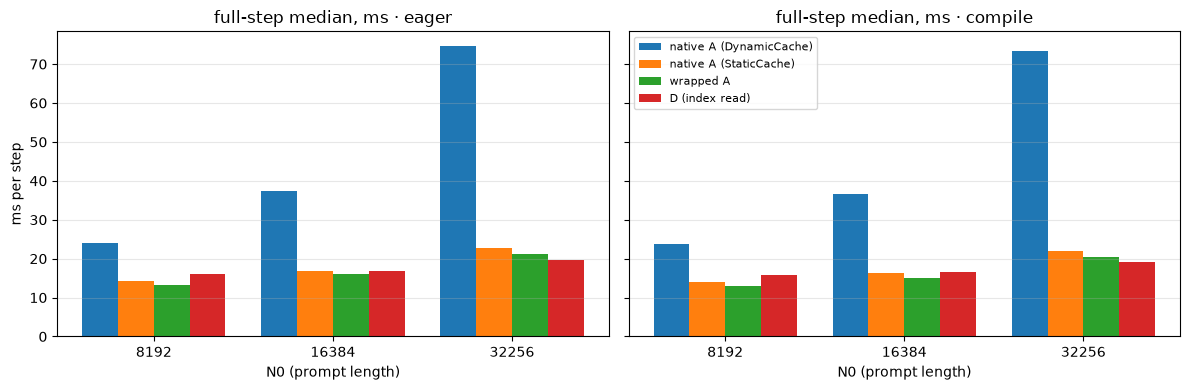

In [8]:
import matplotlib
import matplotlib.pyplot as plt
PATHS = ["native_dynamic", "native_static", "wrapped_full", "sparse"]
LABEL_EN = {"native_dynamic": "native A (DynamicCache)", "native_static": "native A (StaticCache)", "wrapped_full": "wrapped A", "sparse": "D (index read)"}
LABEL = {"native_dynamic": "原生 A · DynamicCache", "native_static": "原生 A · StaticCache", "wrapped_full": "封装 A", "sparse": "D（索引读取）"}
if summary:
    cells_ = [c for c in summary["cells"] if c.get("single_median_ms") is not None]
    N0s = sorted({c["N0"] for c in cells_}); modes = [m_ for m_ in ("eager", "compile") if any(c["mode"] == m_ for c in cells_)]
    print(f"{'N0':>6} {'模式':<8} {'路径':<24} {'Prefill ms':>11} {'单步中位 ms':>12} {'p95':>8} {'n':>4} {'配对比值 D/封装A 中位(范围)':>30} {'≤0.90 循环':>12}")
    for N0 in N0s:
        for mode in modes:
            for p_ in PATHS:
                c = next((c for c in cells_ if c["N0"] == N0 and c["mode"] == mode and c["path"] == p_), None)
                if not c: continue
                pr = c["paired_ratio_vs_wrapped_full"] or {}
                rs = f"{pr.get('median', float('nan')):.3f} ({pr.get('min', float('nan')):.2f}–{pr.get('max', float('nan')):.2f})" if pr else "—"
                print(f"{N0:>6} {mode:<8} {LABEL[p_]:<24} {c['prefill_ms'] or 0:>11.0f} {c['single_median_ms']:>12.2f} {c['single_p95_ms']:>8.2f} {c['single_n']:>4} {rs:>30} {str(pr.get('cycles_at_or_below_0.90', '—')) + '/' + str(pr.get('n_cycles', '—')):>12}")
    fig, axes = plt.subplots(1, len(modes), figsize=(6 * len(modes), 4), sharey=True)
    axes = [axes] if len(modes) == 1 else list(axes)
    w = 0.2
    for ax, mode in zip(axes, modes):
        for k_, p_ in enumerate(PATHS):
            ys = [next((c["single_median_ms"] for c in cells_ if c["N0"] == N0 and c["mode"] == mode and c["path"] == p_), float("nan")) for N0 in N0s]
            ax.bar([i_ + (k_ - 1.5) * w for i_ in range(len(N0s))], ys, w, label=LABEL_EN[p_])
        ax.set_xticks(range(len(N0s))); ax.set_xticklabels([str(n) for n in N0s]); ax.set_xlabel("N0 (prompt length)"); ax.set_title(f"full-step median, ms · {mode}")
        ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("ms per step"); axes[-1].legend(fontsize=8)
    plt.tight_layout()
    show_figure(fig, "2-2", "各路径的完整模型单步耗时")
else:
    print("未执行")


**预测对照。** 把卡片的预测区间与实测放在一张表里。"单层省下的时间"按 G1a 每层数字乘 28 层给出，与实测的整步差值（D − A）并排。

In [9]:
G1A_US = {8192: (110, 195), 16384: (203, 222), 32768: (405, 297)}        # G1a bf16 eager rotating: (A, D_full) µs/层
PRED = {8192: ("35–55", "1.10–1.25"), 16384: ("35–55", "1.08–1.20"), 32256: ("36–58", "0.98–1.15")}
if summary:
    print(f"{'N0':>6} {'模式':<8} {'预测 A ms':>10} {'实测 A ms':>10} {'预测 D/A':>10} {'实测 D/A 中位':>14} {'判定':<6} {'G1a 28层注意力差 D−A ms':>24} {'实测整步差 D−A ms':>18}")
    for N0 in N0s:
        key = 32768 if N0 == 32256 else N0
        a_us, d_us = G1A_US[key]
        for mode in modes:
            A = next((c for c in cells_ if c["N0"] == N0 and c["mode"] == mode and c["path"] == "wrapped_full"), None)
            D = next((c for c in cells_ if c["N0"] == N0 and c["mode"] == mode and c["path"] == "sparse"), None)
            if not (A and D): continue
            ratio = D["paired_ratio_vs_wrapped_full"]["median"]
            lo_, hi_ = (float(x) for x in PRED[N0][1].split("–"))
            alo, ahi = (float(x) for x in PRED[N0][0].split("–"))
            verdict = ("成立" if lo_ <= ratio <= hi_ else "失效") + ("" if alo <= A["single_median_ms"] <= ahi else "（A 量级失效）")
            print(f"{N0:>6} {mode:<8} {PRED[N0][0]:>10} {A['single_median_ms']:>10.2f} {PRED[N0][1]:>10} {ratio:>14.3f} {verdict:<6} {(d_us - a_us) * 28 / 1000:>+24.1f} {D['single_median_ms'] - A['single_median_ms']:>+18.2f}")

    N0 模式          预测 A ms    实测 A ms     预测 D/A      实测 D/A 中位 判定           G1a 28层注意力差 D−A ms       实测整步差 D−A ms
  8192 eager         35–55      13.32  1.10–1.25          1.210 成立（A 量级失效）                     +2.4              +2.80
  8192 compile       35–55      13.08  1.10–1.25          1.225 成立（A 量级失效）                     +2.4              +2.83
 16384 eager         35–55      16.00  1.08–1.20          1.054 失效（A 量级失效）                     +0.5              +0.83
 16384 compile       35–55      15.13  1.08–1.20          1.103 成立（A 量级失效）                     +0.5              +1.56
 32256 eager         36–58      21.21  0.98–1.15          0.930 失效（A 量级失效）                     -3.0              -1.53
 32256 compile       36–58      20.40  0.98–1.15          0.934 失效（A 量级失效）                     -3.0              -1.33


**实测。** eager 固定历史长度下，A 的整步中位为 13.3/16.0/21.2 ms，D 为 16.1/16.8/19.7 ms；配对 D/A 为 1.210/1.054/0.930。32K 的 50 轮中只有 7 轮达到 ≤0.90，未通过预定门槛。

**单层优势为何不能直接变成同等整步收益？** 原来的 Q/K/V 投影、输出投影、MLP 等仍然执行。若只改变注意力读取，整步减少的比例就是“读取阶段省下的时间 ÷ 原整步总时间”。用 $T_{\mathrm{other}}$ 表示两条路径共有的其余计算时间：

$$
\frac{T_{A,\mathrm{read}}-T_{D,\mathrm{read}}}
     {T_{\mathrm{other}}+T_{A,\mathrm{read}}}.
$$

这解释共同计算怎样稀释百分比，但不能解释单层外推的绝对节省为何没有完全兑现。第一课的形状、数据工作集与这里不同；原测量也没有把模型内每项成本独立分离。因此“整步时间减去外部单层时间×28”得到的约 10 ms，不能当作已测出的固定基底。

**代码与剖析能说明到哪一步？** 32K 下 D 比 A 多 422 个非视图 aten 事件；记录只包含 CPU 活动，不能据此把慢归因于 GPU 核数量或 CPU 提交。原生 DynamicCache 每步拼接已有 K/V，确实增加了整段复制工作；32K 连续步中位约 39.3 ms，封装 A 约 20.8 ms，但本实验没有隔离复制成本对差值的贡献。

块编译后配对 D/A 为 0.934，仍未通过门槛。已保存的同形状开发探针曾尝试减少几个操作，预计整步只少约 0.2–0.4 ms，未进入新的正式运行；它不是本表的测速样本，也不作为确定瓶颈的证据。

## 3. 问题三：连续推进时缓存、索引表和执行效率是否稳定

**运行前预测保留**：封装路径首/末 16 步中位相差 ≤5%，斜率绝对值 ≤20 µs/步；k=k0、读取数 68+k0 不变；静态路径内存统计不增长，DynamicCache 随步增长；块编译无重编译。

每条路径输入同一串预先固定的 128 个 token，不根据自身预测改变后续输入。每步前按新的合法长度建名单；表中单步计时前后同步，内存在第 0、16、…、112、127 步采样。四套缓存同时常驻，采样统计不是每方法独占内存。

每条路径重复3段128步序列，各段前恢复起始长度；路径顺序按重复轮次正反交替。序列总时间是逐步同步计时之和，不是无逐步同步的一次整段吞吐测量。

In [10]:
print(excerpt(benchmark_wrapper, "forward", "LabRunner"))
print(excerpt(benchmark_wrapper, "build_step_plan"))

def forward(self, input_ids: torch.Tensor, *, logits_to_keep: int = 1) -> torch.Tensor:
        st, cache = self.state, self.state.cache
        B, T = input_ids.shape
        if B != cache.batch:
            raise ValueError("batch size differs from the cache")
        start = cache.valid_length
        if T == 1 and st.mode == "sparse":
            if st.k0 is None:
                raise RuntimeError("call state.begin_request(rho) before the first sparse decode step")
            st.plan = build_step_plan(cache, start + 1, st.k0)
        self.holder.state = st
        out = self.model(input_ids=input_ids, position_ids=self.positions[start:start + T].unsqueeze(0),
                         attention_mask=MASK_BYPASS, use_cache=False, logits_to_keep=logits_to_keep)
        cache.advance(T)
        return out.logits
def build_step_plan(cache: LabCache, legal_length: int, k0: int) -> StepPlan:
    """F ∪ candidate domain for a decode step whose legal range is [0, legal_length). Device-sid

    N0 模式       路径                            每步中位 ms      首16      末16     末/首    斜率 µs/步    128步合计 ms    k 末步     读取数 末步
  8192 compile  原生 A · DynamicCache             16.44    16.41    16.54   1.008       -2.8         2103    None       None
  8192 compile  原生 A · StaticCache              13.86    13.88    13.87   0.999       -1.1         1775    None       None
  8192 compile  封装 A                            13.00    13.04    12.93   0.992       -3.2         1665    None       None
  8192 compile  D（索引读取）                         16.80    16.45    16.86   1.025       +0.7         2192     256        324
  8192 eager    原生 A · DynamicCache             16.66    16.66    16.63   0.998       -2.3         2147    None       None
  8192 eager    原生 A · StaticCache              14.14    14.10    14.11   1.000       -2.3         1813    None       None
  8192 eager    封装 A                            13.39    13.50    13.41   0.994       -2.1         1716    None       None
  8192 eager    


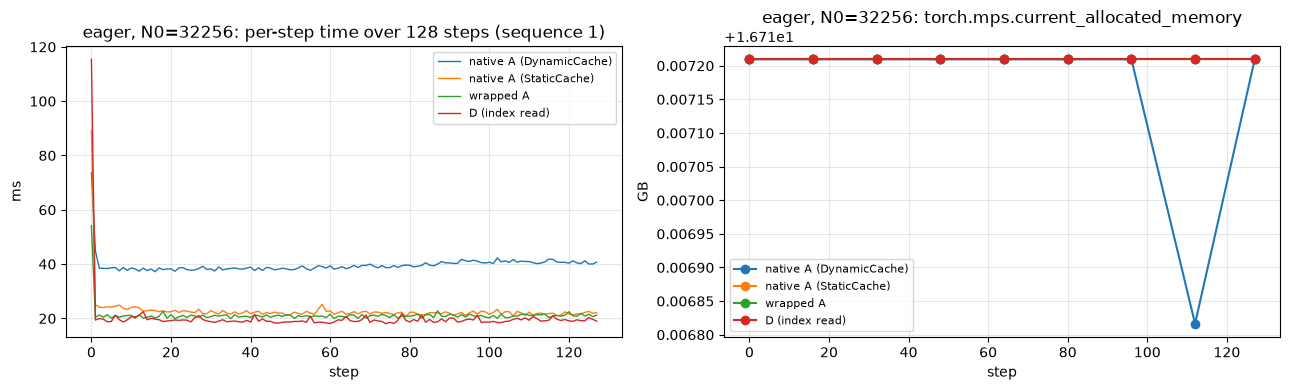

In [11]:
if summary:
    seq = [c for c in summary["cells"] if c.get("seq_step_median_ms") is not None]
    print(f"{'N0':>6} {'模式':<8} {'路径':<24} {'每步中位 ms':>12} {'首16':>8} {'末16':>8} {'末/首':>7} {'斜率 µs/步':>10} {'128步合计 ms':>12} {'k 末步':>7} {'读取数 末步':>10}")
    for c in sorted(seq, key=lambda c: (c["N0"], c["mode"], PATHS.index(c["path"]))):
        print(f"{c['N0']:>6} {c['mode']:<8} {LABEL[c['path']]:<24} {c['seq_step_median_ms']:>12.2f} {c['seq_first16_ms']:>8.2f} {c['seq_last16_ms']:>8.2f} {c['seq_last16_ms']/c['seq_first16_ms']:>7.3f} {c['seq_slope_us_per_step']:>+10.1f} {c['seq_total_ms_median']:>12.0f} {str(c['k_last']):>7} {str(c['selected_last']):>10}")
    Nmax = max(c["N0"] for c in seq)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for p_ in PATHS:
        c = next((c for c in seq if c["N0"] == Nmax and c["mode"] == "eager" and c["path"] == p_), None)
        if c and c["seq_series_ms"]:
            axes[0].plot(c["seq_series_ms"][0], label=LABEL_EN[p_], lw=1)
            mem_ = [m_ for m_ in (c["seq_memory"][0] or []) if m_]
            if mem_:
                axes[1].plot([m_["step"] for m_ in mem_], [m_["current_allocated_bytes"] / 1e9 for m_ in mem_], marker="o", label=LABEL_EN[p_])
    axes[0].set_title(f"eager, N0={Nmax}: per-step time over 128 steps (sequence 1)"); axes[0].set_xlabel("step"); axes[0].set_ylabel("ms"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)
    axes[1].set_title(f"eager, N0={Nmax}: torch.mps.current_allocated_memory"); axes[1].set_xlabel("step"); axes[1].set_ylabel("GB"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
    plt.tight_layout()
    show_figure(fig, "2-3", "连续 128 步的耗时与已分配设备内存")


In [12]:
print("剖析记录仅用于说明实际调用；CPU 事件数不能直接定位 GPU 耗时来源。")
with details('展开逐长度的 CPU 剖析与编译记录'):
    # 剖析证据（与计时分开跑）：算子数、CPU 侧时间、触及合法长度 / 容量的 matmul 类算子
    if summary:
        import glob as _g
        for rid in summary["runs"]:
            for sp in sorted(_g.glob(str(root / f"runs/{rid}/summary.json"))):
                s_ = json.loads(Path(sp).read_text())
                for block in s_["lengths"]:
                    if "profiles" not in block: continue
                    print(f"\n{rid} N0={block['N0']}：")
                    for p_, pf in block["profiles"].items():
                        if pf.get("status") == "error": print("  ", p_, "剖析错误", pf["error_type"]); continue
                        wall = next((c["single_median_ms"] for c in summary["cells"] if c["run_id"] == rid and c["N0"] == block["N0"] and c["mode"] == "eager" and c["path"] == p_), None)
                        print(f"  {LABEL[p_]:<24} aten 算子 {pf['aten_ops']:>5}（非视图 {pf.get('top_level_ops', '—')}）  CPU 侧自时间 {pf.get('cpu_self_total_ms', float('nan')):6.2f} ms  对比整步墙钟 {wall if wall is None else round(wall, 2)} ms  "
                              f"触及长度的 matmul 类算子 {len(pf['length_matmul_ops'])}  top-k {pf['topk_calls']}  index_select {pf['index_select_calls']}  SDPA {pf['sdpa_dispatch']}")
                    if block.get("compile"):
                        ci = block["compile"]; print(f"  块编译（MLP + RMSNorm，四路径共用）: {ci.get('status')}，首调用 {ci.get('first_call_s', float('nan')):.2f} s，对 eager 词表分数 max|Δ| {ci.get('max_abs_diff_vs_eager_logits')}，测量期间 dynamo 新图 {ci.get('dynamo_counters_delta', {}).get('stats', {}).get('unique_graphs')}")
        print("\n注：本地 runs/ 不随仓库分发；没有 runs/ 时本格只打印 run id。")

剖析记录仅用于说明实际调用；CPU 事件数不能直接定位 GPU 耗时来源。


**时间和名额。** 所测模式中，封装 A 首/末 16 步中位相差不超过约 0.9%，D 不超过约 2.8%；但 32K D 的斜率为 eager −30.3、compile −27.3 µs/步，未满足原先的绝对斜率 ≤20 条件。它们表现为下行趋势，不能因此说持续变慢，也不能把整条预测写成“全部成立”。k0 为 256/512/1008，实际读取数为 68+k0，记录中没有随步扩大。

**内存统计。** `current_allocated_memory` 统计张量占用，不含分配器池中未使用的缓存块；`driver_allocated_memory` 才包括池缓存及 MPS/MPSGraph 分配。这里已对照本机库实现与 [PyTorch 2.14 的张量内存接口](https://docs.pytorch.org/docs/2.14/generated/torch.mps.current_allocated_memory.html)、[驱动内存接口](https://docs.pytorch.org/docs/2.14/generated/torch.mps.driver_allocated_memory.html)。不能用“缓存池复用”直接解释前者没有上升。

32K 档中，张量内存采样约 16.7168–16.7172 GB，驱动统计约 24.907 GB；这些数只属于这一长度档。DynamicCache 的逻辑 K/V 每多一个 token 增加 `28×2×8×128×2=114688` 字节，128 步增加约 14.68 MB。当前总量采样没有分离出这部分增长，支持的结论仅是“本次采样未见持续总量上升”，不构成内存无泄漏证明。

eager 没有编译对象；块编译期间未记录新图或重编译错误。128 步在最大长度档只把合法长度从 32256 推到 32384，不能代表更长推进或容量换档。

## 4. 预测对照与决策

| 原预测 | 对应观察 | 本次判断 |
|---|---|---|
| A 整步 35–55 ms，由 CPU 提交主导 | 13.3/16.0/21.2 ms；仅有 CPU 活动剖析 | 时间量级预测失效；主导原因未确定 |
| D/A 在 8K/16K/32K 为 1.10–1.25 / 1.08–1.20 / 0.98–1.15；替代预测 32K 为 0.85–0.95 | eager 配对比值 1.210/1.054/0.930 | 8K 主预测成立，16K 更低，32K 主预测失效、落入替代范围 |
| 比值对长度依赖弱 | 从 1.210 降到 0.930 | 不成立 |
| 封装首/末 16 步中位差 ≤5% | A ≤0.9%，D ≤2.8% | 本批成立 |
| 绝对斜率 ≤20 µs/步 | 32K D 为 −30.3 / −27.3 | 未全部成立；这是下行趋势 |
| 名额固定、块编译无重编译 | k0 和读取数不变，未记录新图 | 本批成立 |
| DynamicCache 内存采样随步上升 | 逻辑载荷增长，总量采样未清楚反映 | 不能将“总量平坦”当作载荷不增长 |
| float32 数值全过且余量达一个量级；bf16 分数差约 0.1–0.5 | float32 按门槛通过，缓存余量不足一个量级；bf16 历史比较约 0.16–0.30 | 部分成立，参照与修订规则见第 1 节 |
| 块编译可把 A 降到 20–35 ms | A 原本已更快，编译收益约 2–5% | 能编译，原量级前提不成立 |

**阶段决定。** 接入、缓存与数值检查完成；性能状态 `correct_but_not_faster` 指没有达到预定的稳定 10% 改善门槛，不是字面上任何设置都不快。32K eager 的配对改善约 7%，索引器仍未训练，不能当作可用答题方案。

课程在这里保留负结果：完整模型中的时间收益低于单层粗估，具体成本尚未分离。没有证据说明融合内核或更换平台就一定越过门槛；本阶段停止速度优化，后续质量实验见第三课。